# 01 - Data Exploration

## Project: Retail Sales Forecasting

### Objectives
- Understand the dataset structure.
- Explore data types and statistical properties.
- Identify missing values and duplicates.
- Analyze sales distributions and patterns.
- Investigate relationships between features and sales.

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 3.1.1
Scikit-learn: 1.9.1


## 1. Loading the datasets

In [105]:
# Define project paths
from pathlib import Path
ROOT_DIR = Path.cwd()

if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

DATA_DIR = ROOT_DIR / "data" / "raw"

# Load datasets
train = pd.read_csv(DATA_DIR / "train.csv")
store = pd.read_csv(DATA_DIR / "store.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

# Display confirmation
print("Datasets loaded successfully!")

Datasets loaded successfully!


C:\Users\mrymh\AppData\Local\Temp\ipykernel_4800\2826480446.py:11: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(DATA_DIR / "train.csv")


In [106]:
print("TRAIN DATASET")
display(train.head())

print("STORE DATASET")
display(store.head())

print("TEST DATASET")
display(test.head())

TRAIN DATASET


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


STORE DATASET


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


TEST DATASET


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [107]:
# shape returns (number_of_rows, number_of_columns)
print("Train shape:", train.shape)
print("Store shape:", store.shape)
print("Test shape:", test.shape)

Train shape: (1017209, 9)
Store shape: (1115, 10)
Test shape: (41088, 8)


In [108]:
train.info()
store.info()
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB
<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment          

In [109]:
# Check missing values in each dataset

print("Missing values in TRAIN:")
print(train.isnull().sum())

print("\nMissing values in STORE:")
print(store.isnull().sum())

print("\nMissing values in TEST:")
print(test.isnull().sum())

Missing values in TRAIN:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in STORE:
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

Missing values in TEST:
Id                0
Store             0
DayOfWeek         0
Date              0
Open             11
Promo             0
StateHoliday      0
SchoolHoliday     0
dtype: int64


In [110]:
#calculate the percentage of missing
def missing_values_report(df):
    missing = pd.DataFrame({
        'Missing Values': df.isnull().sum(),
        'Percentage (%)': (df.isnull().sum() / len(df)) * 100
    })

    return missing[missing['Missing Values'] > 0].sort_values(
        by='Percentage (%)',
        ascending=False
    )

print("TRAIN:")
display(missing_values_report(train))

print("STORE:")
display(missing_values_report(store))

print("TEST:")
display(missing_values_report(test))

TRAIN:


,Missing Values,Percentage (%)


STORE:


,Missing Values,Percentage (%)
Promo2SinceYear,544,48.789238
Promo2SinceWeek,544,48.789238
PromoInterval,544,48.789238
CompetitionOpenSinceMonth,354,31.748879
CompetitionOpenSinceYear,354,31.748879
CompetitionDistance,3,0.269058


TEST:


,Missing Values,Percentage (%)
Open,11,0.026772


In [111]:
#Check duplicate records
print("Train duplicates:", train.duplicated().sum())
print("Store duplicates:", store.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

Train duplicates: 0
Store duplicates: 0
Test duplicates: 0


In [112]:
#check unique identifier in the store dataset
print("Unique stores:", store['Store'].nunique())
print("Total store records:", len(store))

Unique stores: 1115
Total store records: 1115


In [113]:
# Convert Date columns to datetime

train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])

print("Training period:")
print(train['Date'].min(), "to", train['Date'].max())

print("\nTesting period:")
print(test['Date'].min(), "to", test['Date'].max())

Training period:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Testing period:
2015-08-01 00:00:00 to 2015-09-17 00:00:00


## 2. Missing Values Investigation

In [114]:
# Relationship between Promo2 and missing promotional information

print(pd.crosstab(
    store['Promo2'],
    store['Promo2SinceWeek'].isnull(),
    margins=True
))

Promo2SinceWeek  False  True   All
Promo2                            
0                    0   544   544
1                  571     0   571
All                571   544  1115


In [115]:
# Check missing competition opening dates

print(pd.crosstab(
    store['CompetitionOpenSinceYear'].isnull(),
    store['CompetitionOpenSinceMonth'].isnull(),
    margins=True
))

CompetitionOpenSinceMonth  False  True   All
CompetitionOpenSinceYear                    
False                        761     0   761
True                           0   354   354
All                          761   354  1115


In [116]:
store[store['CompetitionDistance'].isnull()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [117]:
# Display records with missing Open values

missing_open = test[test['Open'].isnull()]

display(missing_open)

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


## 3. Target Variable Analysis

In [118]:
# Statistical summary of numerical columns

display(train[['Sales', 'Customers']].describe())

,Sales,Customers
count,1.017209e+06,1.017209e+06
mean,5.773819e+03,6.331459e+02
std,3.849926e+03,4.644117e+02
min,0.000000e+00,0.000000e+00
25%,3.727000e+03,4.050000e+02
50%,5.744000e+03,6.090000e+02
75%,7.856000e+03,8.370000e+02
max,4.155100e+04,7.388000e+03


In [119]:
# Check sales when stores are closed

print("Closed store records:", (train['Open'] == 0).sum())

print("Records with zero sales:", (train['Sales'] == 0).sum())

print("Open stores with zero sales:",
      ((train['Open'] == 1) & (train['Sales'] == 0)).sum())

Closed store records: 172817
Records with zero sales: 172871
Open stores with zero sales: 54


In [120]:
#check categorial features
categorical_columns = [
    'StoreType',
    'Assortment',
    'PromoInterval'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(store[col].value_counts(dropna=False))


StoreType:
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Assortment:
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

PromoInterval:
PromoInterval
NaN                 544
Jan,Apr,Jul,Oct     335
Feb,May,Aug,Nov     130
Mar,Jun,Sept,Dec    106
Name: count, dtype: int64


In [121]:
print("StateHoliday:")
print(train['StateHoliday'].value_counts(dropna=False))

print("\nSchoolHoliday:")
print(train['SchoolHoliday'].value_counts(dropna=False))

StateHoliday:
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

SchoolHoliday:
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64


### 3.1 Sales Distribution Analysis

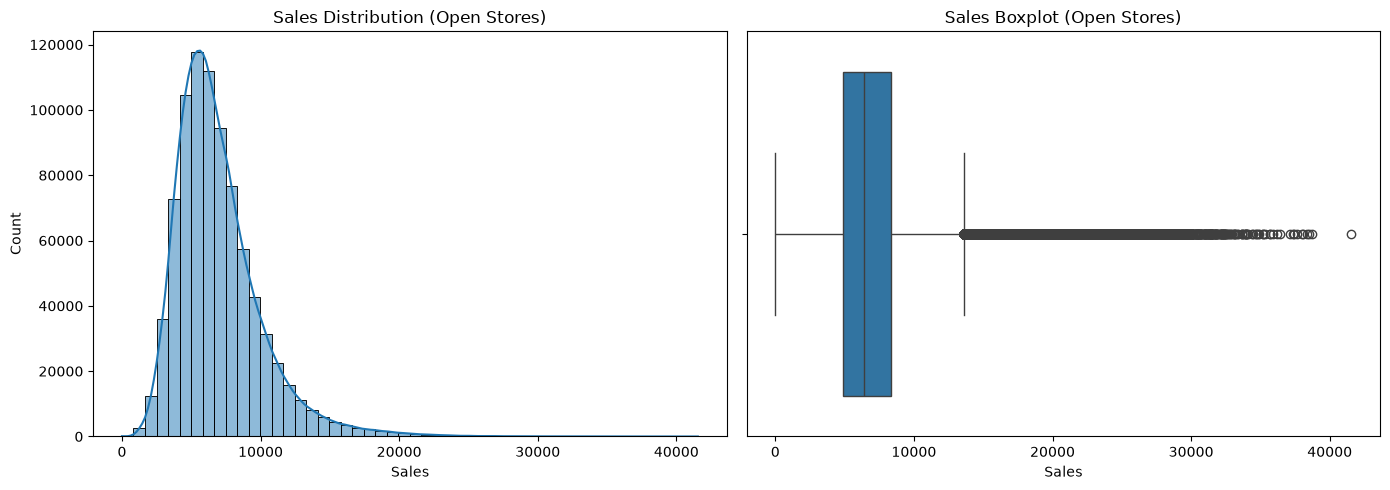

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

# Consider only open stores
open_stores = train[train['Open'] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales distribution
sns.histplot(
    open_stores['Sales'],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Sales Distribution (Open Stores)')
axes[0].set_xlabel('Sales')

# Boxplot
sns.boxplot(
    x=open_stores['Sales'],
    ax=axes[1]
)

axes[1].set_title('Sales Boxplot (Open Stores)')
axes[1].set_xlabel('Sales')

plt.tight_layout()
plt.show()

### 3.2 Sales Patterns Across Weekdays

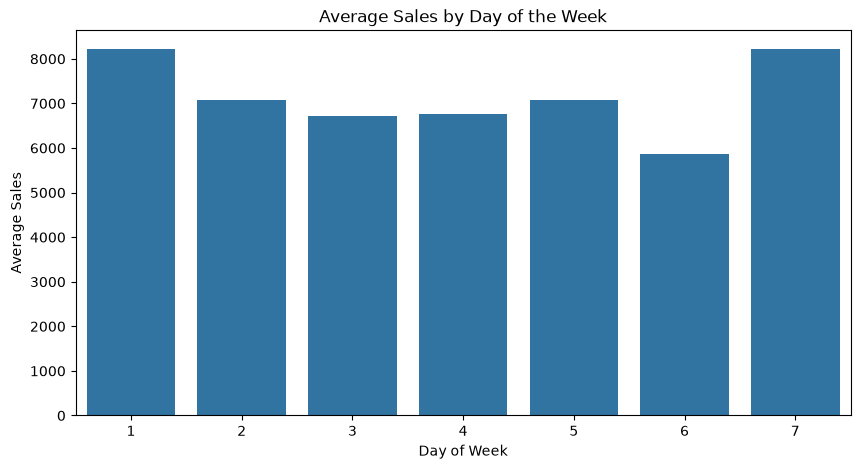

In [123]:
# Average sales for each day of the week
sales_by_day = train[train['Open'] == 1].groupby('DayOfWeek')['Sales'].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=sales_by_day.index,
    y=sales_by_day.values
)

plt.title('Average Sales by Day of the Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Sales')
plt.show()

### 3.2 Sales Analysis by Promotion

In [124]:
sales_by_promo = train[train['Open'] == 1].groupby('Promo')['Sales'].mean()

print(sales_by_promo)

Promo
0    5929.407603
1    8228.281239
Name: Sales, dtype: float64


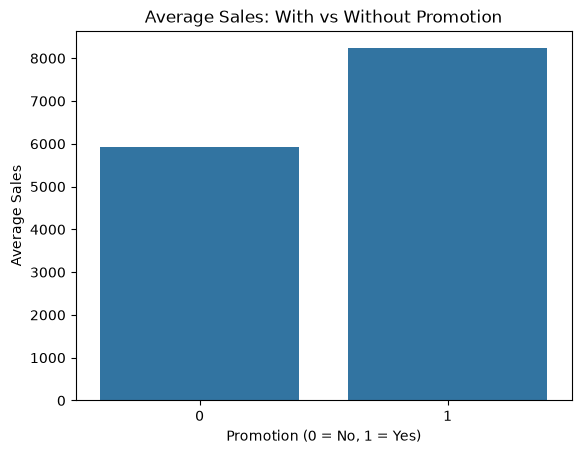

In [125]:
sns.barplot(
    x=sales_by_promo.index,
    y=sales_by_promo.values
)

plt.title('Average Sales: With vs Without Promotion')
plt.xlabel('Promotion (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.show()

**Key Findings: Sales by Promotion**

- Average sales on promotion days (8,228) are considerably higher than on non-promotion days (5,929).
- Promotion days show approximately 38.8% higher average sales.
- This suggests that promotional activities are positively associated with store sales.

**Conclusion:** Promotions appear to be an important factor associated with daily sales performance. Further analysis is needed to understand their impact independently of other factors.

In [126]:
# Merge training data with store information
train_merged = train.merge(
    store[['Store', 'StoreType']],
    on='Store',
    how='left'
)

# Calculate average sales by store type
sales_by_store_type = (
    train_merged[train_merged['Open'] == 1]
    .groupby('StoreType')['Sales']
    .mean()
)

print(sales_by_store_type)

StoreType
a     6925.167661
b    10231.407505
c     6932.512755
d     6822.141881
Name: Sales, dtype: float64


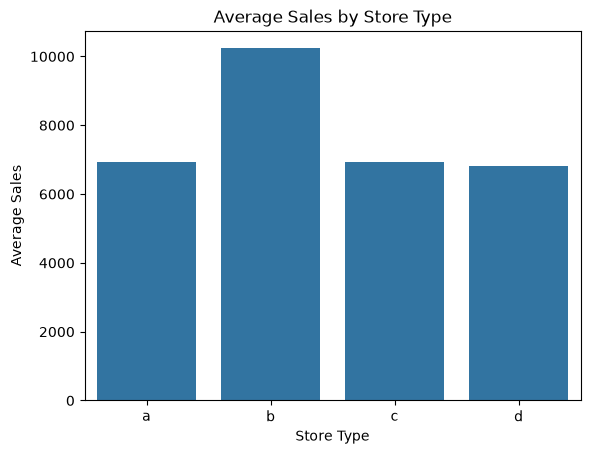

In [127]:
sns.barplot(
    x=sales_by_store_type.index,
    y=sales_by_store_type.values
)

plt.title('Average Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales')
plt.show()

**Key Findings: Average Sales by Store Type**

- Store Type B has the highest average daily sales (approximately 10,231).
- Store Type D has the lowest average daily sales (approximately 6,822).
- Store Types A and C have relatively similar average sales.
- Store Type B generates approximately 48% higher average sales than Store Type A.

**Conclusion:** Store type appears to be an important factor associated with sales performance. This feature should be retained for further analysis and model development.

In [128]:
train_merged = train.merge(
    store,
    on='Store',
    how='left'
)

sales_by_assortment = (
    train_merged[train_merged['Open'] == 1]
    .groupby('Assortment')['Sales']
    .mean()
)

print(sales_by_assortment)

Assortment
a    6621.017039
b    8639.346322
c    7300.526339
Name: Sales, dtype: float64


In [129]:
print(train_merged.shape)
print(train_merged.columns.tolist())

(1017209, 18)
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


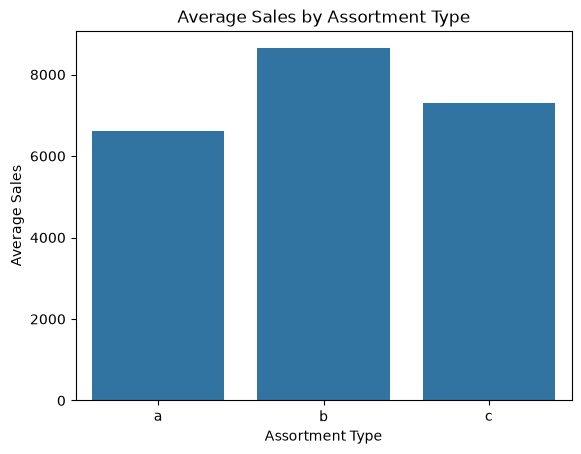

In [130]:
sns.barplot(
    x=sales_by_assortment.index,
    y=sales_by_assortment.values
)

plt.title('Average Sales by Assortment Type')
plt.xlabel('Assortment Type')
plt.ylabel('Average Sales')
plt.show()

**Key Findings: Average Sales by Assortment Type**

- Assortment B has the highest average daily sales (approximately 8,639).
- Assortment A has the lowest average daily sales (approximately 6,621).
- Assortment C performs between the other two categories.
- Assortment B generates approximately 30.5% higher average sales than Assortment A.

**Conclusion:** Assortment type appears to be associated with sales performance and should be considered as a potentially useful feature for the forecasting model.

In [131]:
sales_by_school_holiday = (
    train[train['Open'] == 1]
    .groupby('SchoolHoliday')['Sales']
    .mean()
)

print(sales_by_school_holiday)

SchoolHoliday
0    6896.782411
1    7200.181650
Name: Sales, dtype: float64


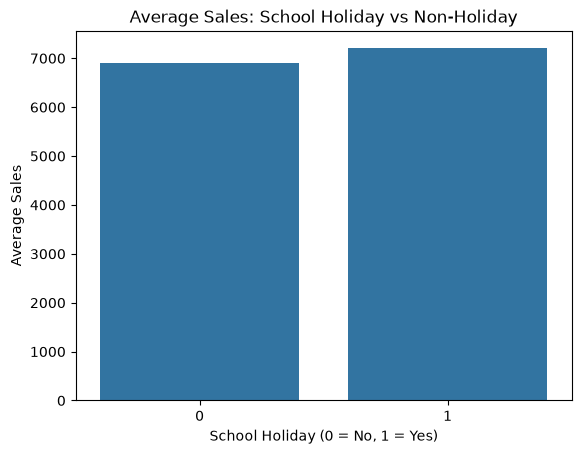

In [132]:
sns.barplot(
    x=sales_by_school_holiday.index,
    y=sales_by_school_holiday.values
)

plt.title('Average Sales: School Holiday vs Non-Holiday')
plt.xlabel('School Holiday (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.show()

In [133]:
# Consider only records where stores are open
open_stores = train[train['Open'] == 1]

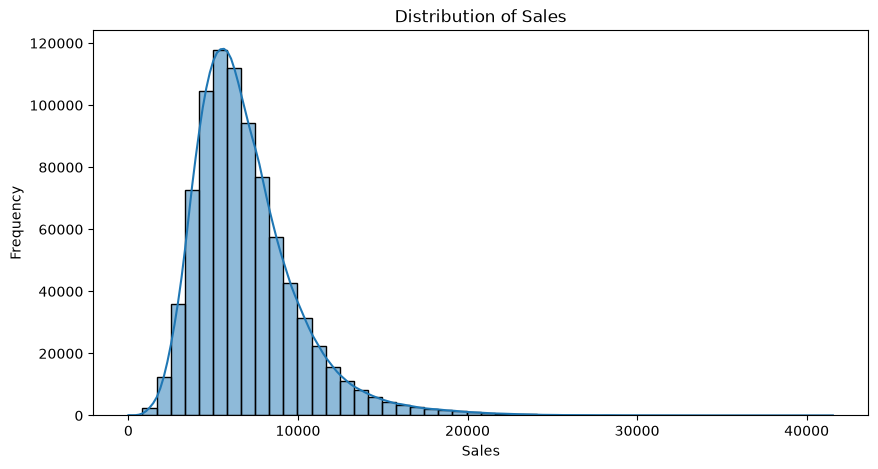

In [134]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=open_stores,
    x='Sales',
    bins=50,
    kde=True
)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

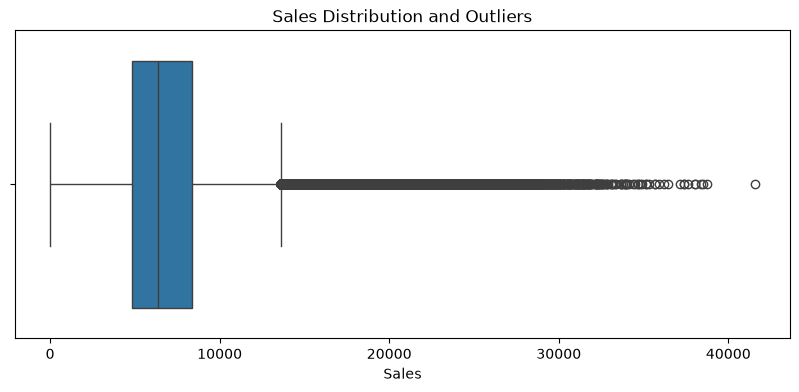

In [135]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=open_stores['Sales'])

plt.title('Sales Distribution and Outliers')
plt.xlabel('Sales')
plt.show()

In [136]:
train['Date'] = pd.to_datetime(train['Date'])

In [137]:
# Extract year and month
train['YearMonth'] = train['Date'].dt.to_period('M')

# Calculate average sales per open store-day
monthly_sales = (
    train[train['Open'] == 1]
    .groupby('YearMonth')['Sales']
    .mean()
)

print(monthly_sales)

YearMonth
2013-01    6239.641380
2013-02    6428.597796
2013-03    7212.834110
2013-04    6579.319656
2013-05    7076.217960
2013-06    6467.051428
2013-07    6923.154611
2013-08    6595.927627
2013-09    6363.388121
2013-10    6473.347016
2013-11    6904.509503
2013-12    8613.455299
2014-01    6539.402563
2014-02    6678.038182
2014-03    6654.021442
2014-04    7226.782207
2014-05    6948.119518
2014-06    7250.660066
2014-07    6891.479689
2014-08    6714.305191
2014-09    6756.588279
2014-10    6757.320303
2014-11    7539.603854
2014-12    8603.805210
2015-01    6913.177694
2015-02    6660.270408
2015-03    7071.240818
2015-04    7349.110170
2015-05    7308.496793
2015-06    7295.618795
2015-07    7033.344905
Freq: M, Name: Sales, dtype: float64


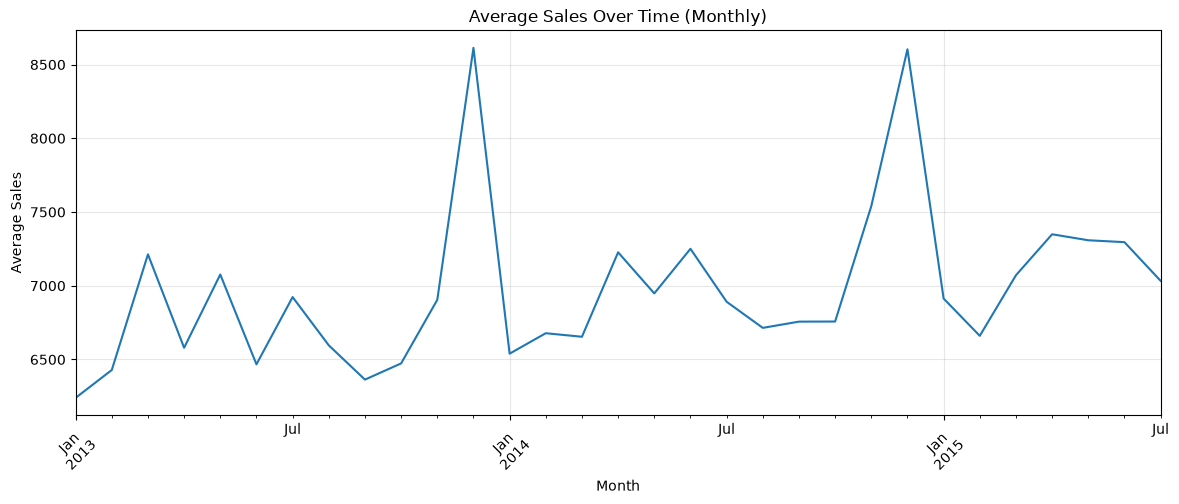

In [138]:
plt.figure(figsize=(14, 5))

monthly_sales.plot()

plt.title('Average Sales Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

In [139]:
yearly_sales = (
    train[train['Open'] == 1]
    .groupby(train[train['Open'] == 1]['Date'].dt.year)['Sales']
    .mean()
)

print(yearly_sales)

Date
2013    6814.392025
2014    7025.404201
2015    7088.126648
Name: Sales, dtype: float64


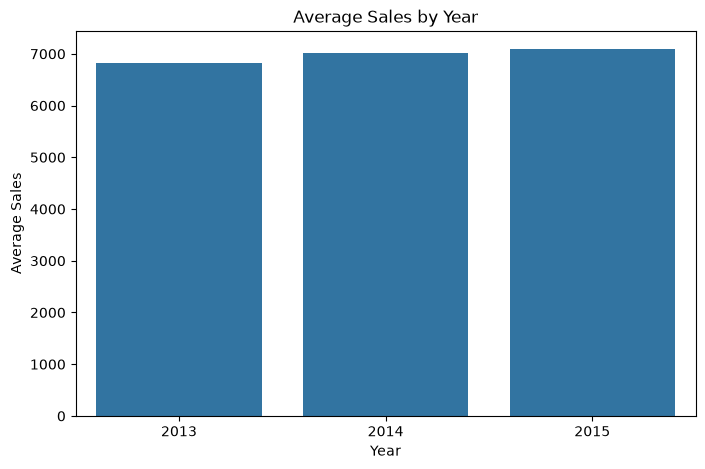

In [140]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=yearly_sales.index,
    y=yearly_sales.values
)

plt.title('Average Sales by Year')
plt.xlabel('Year')
plt.ylabel('Average Sales')
plt.show()

In [141]:
train['DayOfMonth'] = train['Date'].dt.day

In [142]:
sales_by_day_of_month = (
    train[train['Open'] == 1]
    .groupby('DayOfMonth')['Sales']
    .mean()
)

print(sales_by_day_of_month)

DayOfMonth
1     8053.674102
2     7987.452335
3     7765.296991
4     7745.844134
5     7554.982112
6     7149.914351
7     7101.113826
8     6785.121061
9     6499.276895
10    6429.182961
11    6087.881843
12    6186.034047
13    6570.115406
14    6606.648700
15    7018.545523
16    7314.079684
17    7283.898949
18    7340.267275
19    7115.279322
20    6955.004553
21    6693.696159
22    6544.690081
23    6498.037037
24    5915.626283
25    5967.839608
26    6189.771018
27    6636.996208
28    6943.025241
29    7512.799109
30    8354.463914
31    7577.234928
Name: Sales, dtype: float64


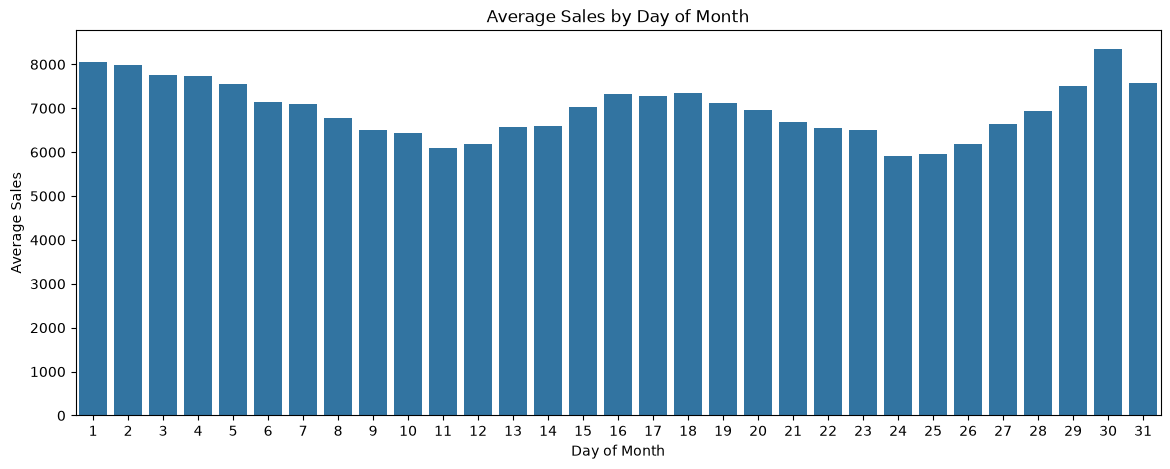

In [143]:
plt.figure(figsize=(14, 5))

sns.barplot(
    x=sales_by_day_of_month.index,
    y=sales_by_day_of_month.values
)

plt.title('Average Sales by Day of Month')
plt.xlabel('Day of Month')
plt.ylabel('Average Sales')
plt.show()

In [144]:
correlation = train[train['Open'] == 1][
    ['Sales', 'Customers']
].corr()

print(correlation)

              Sales  Customers
Sales      1.000000   0.823597
Customers  0.823597   1.000000


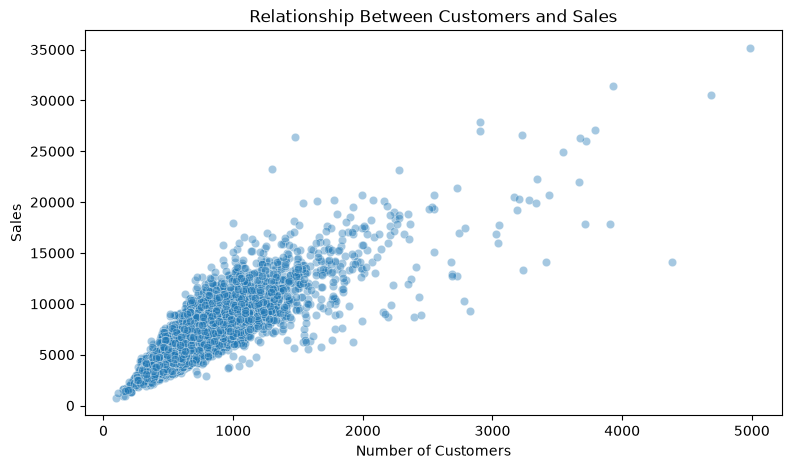

In [145]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=open_stores.sample(5000, random_state=42),
    x='Customers',
    y='Sales',
    alpha=0.4
)

plt.title('Relationship Between Customers and Sales')
plt.xlabel('Number of Customers')
plt.ylabel('Sales')
plt.show()

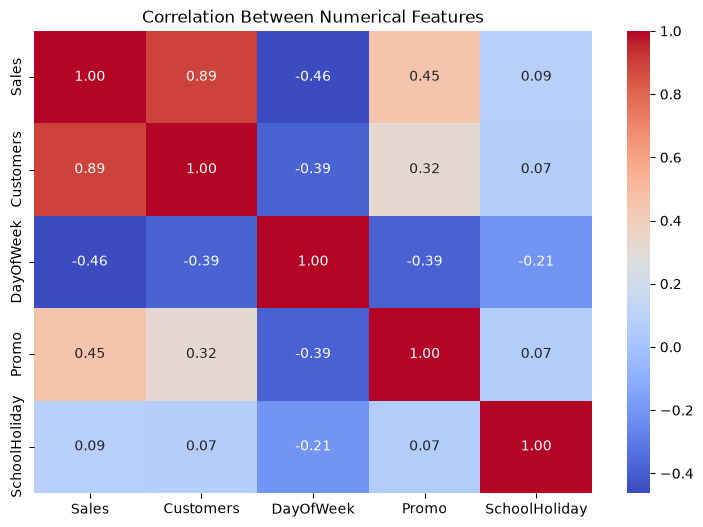

In [146]:
numeric_features = [
    'Sales',
    'Customers',
    'DayOfWeek',
    'Promo',
    'SchoolHoliday'
]

correlation_matrix = train_merged[numeric_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Features')
plt.show()

In [147]:
print(train_merged.columns.tolist())

['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [148]:
sales_by_state_holiday = (
    train_merged[train_merged['Open'] == 1]
    .groupby('StateHoliday')['Sales']
    .mean()
)

print(sales_by_state_holiday)

StateHoliday
0    6701.492117
0    6992.158856
a    8487.471182
b    9887.889655
c    9743.746479
Name: Sales, dtype: float64


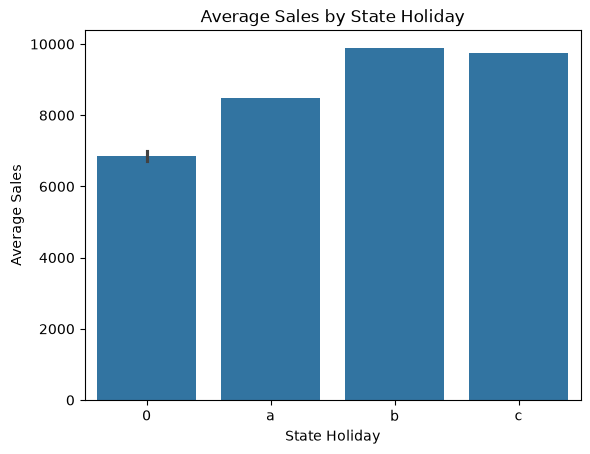

In [149]:
sns.barplot(
    x=sales_by_state_holiday.index,
    y=sales_by_state_holiday.values
)

plt.title('Average Sales by State Holiday')
plt.xlabel('State Holiday')
plt.ylabel('Average Sales')
plt.show()

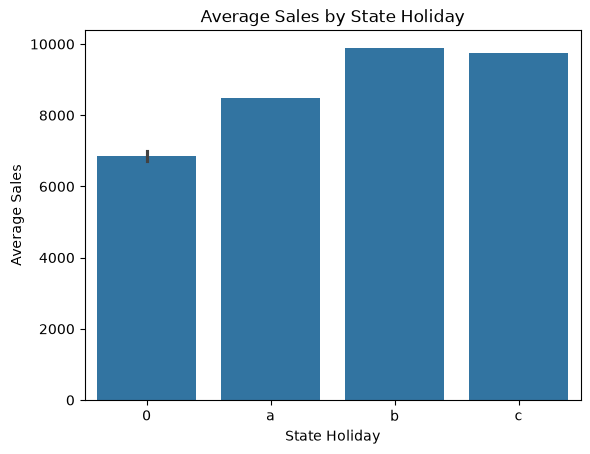

In [150]:
sns.barplot(
    x=sales_by_state_holiday.index,
    y=sales_by_state_holiday.values
)

plt.title('Average Sales by State Holiday')
plt.xlabel('State Holiday')
plt.ylabel('Average Sales')
plt.show()

In [151]:
print(train_merged['StateHoliday'].unique())

print(train_merged['StateHoliday'].value_counts(dropna=False))

['0' 'a' 'b' 'c' 0]
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64


In [152]:
train_merged['StateHoliday'] = (
    train_merged['StateHoliday'].astype(str)
)

print(train_merged['StateHoliday'].unique())

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str


In [153]:
sales_by_state_holiday = (
    train_merged[train_merged['Open'] == 1]
    .groupby('StateHoliday')['Sales']
    .mean()
)

print(sales_by_state_holiday)

StateHoliday
0    6953.515034
a    8487.471182
b    9887.889655
c    9743.746479
Name: Sales, dtype: float64


StoreType
a     6925.167661
b    10231.407505
c     6932.512755
d     6822.141881
Name: Sales, dtype: float64


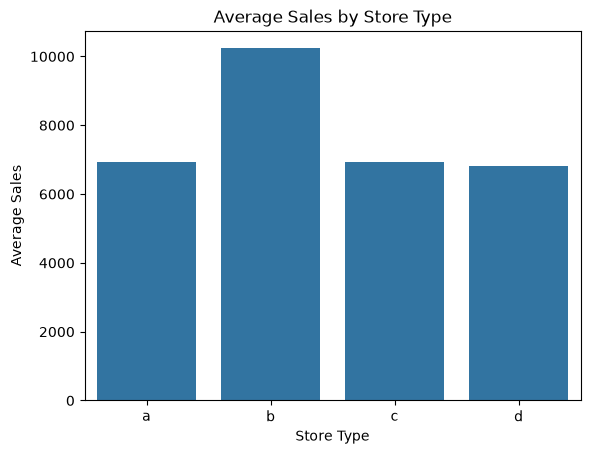

In [154]:
sales_by_store_type = (
    train_merged[train_merged['Open'] == 1]
    .groupby('StoreType')['Sales']
    .mean()
)

print(sales_by_store_type)

sns.barplot(
    x=sales_by_store_type.index,
    y=sales_by_store_type.values
)

plt.title('Average Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales')
plt.show()

In [155]:
sales_by_promo = (
    train_merged[train_merged['Open'] == 1]
    .groupby('Promo')['Sales']
    .mean()
)

print(sales_by_promo)

Promo
0    5929.407603
1    8228.281239
Name: Sales, dtype: float64


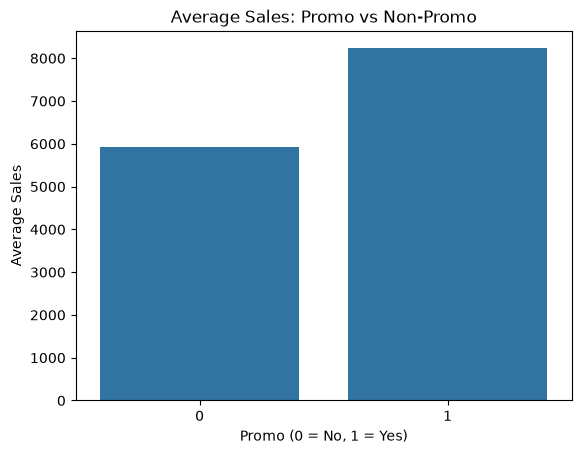

In [159]:
sns.barplot(
    x=sales_by_promo.index,
    y=sales_by_promo.values
)

plt.title('Average Sales: Promo vs Non-Promo')
plt.xlabel('Promo (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.show()

In [160]:
print(train_merged.columns.tolist())


['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


CompetitionDistanceGroup
0-1km      7301.654210
1-5km      6836.022135
5-10km     6742.587896
10-20km    6732.882961
20km+      7026.720824
Name: Sales, dtype: float64


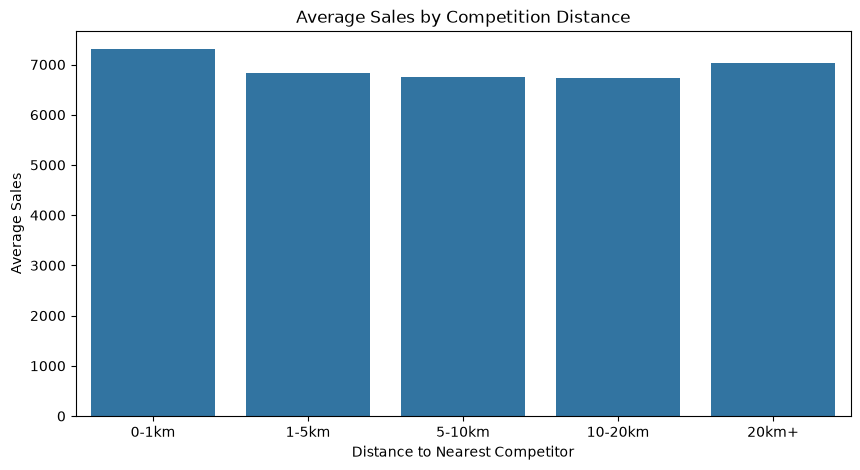

In [161]:

# Average sales by competition distance
open_stores = train_merged[train_merged['Open'] == 1].copy()

# Create distance groups
open_stores['CompetitionDistanceGroup'] = pd.cut(
    open_stores['CompetitionDistance'],
    bins=[0, 1000, 5000, 10000, 20000, float('inf')],
    labels=['0-1km', '1-5km', '5-10km', '10-20km', '20km+']
)

sales_by_competition = (
    open_stores.groupby(
        'CompetitionDistanceGroup',
        observed=True
    )['Sales']
    .mean()
)

print(sales_by_competition)

# Visualize
plt.figure(figsize=(10, 5))

sns.barplot(
    x=sales_by_competition.index,
    y=sales_by_competition.values
)

plt.title('Average Sales by Competition Distance')
plt.xlabel('Distance to Nearest Competitor')
plt.ylabel('Average Sales')
plt.show()


Promo2
0    7350.557935
1    6558.386062
Name: Sales, dtype: float64


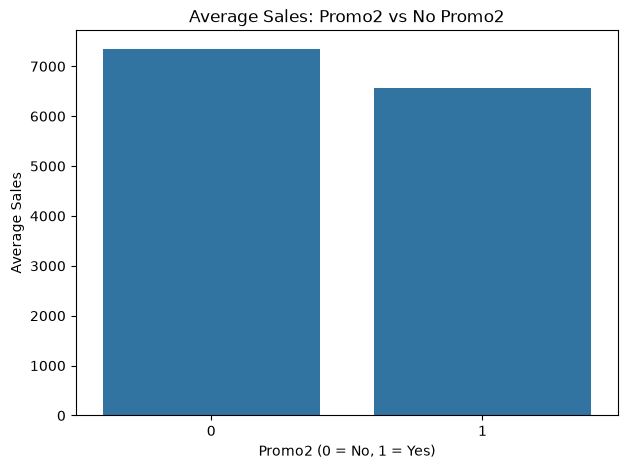

In [162]:

# Average sales by Promo2 participation
sales_by_promo2 = (
    open_stores.groupby('Promo2')['Sales']
    .mean()
)

print(sales_by_promo2)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=sales_by_promo2.index,
    y=sales_by_promo2.values
)

plt.title('Average Sales: Promo2 vs No Promo2')
plt.xlabel('Promo2 (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.show()


PromoInterval
NaN                 508031
Jan,Apr,Jul,Oct     293122
Feb,May,Aug,Nov     118596
Mar,Jun,Sept,Dec     97460
Name: count, dtype: int64
PromoInterval
NaN                 7350.557935
Jan,Apr,Jul,Oct     6725.978932
Feb,May,Aug,Nov     6426.907994
Mar,Jun,Sept,Dec    6214.501209
Name: Sales, dtype: float64


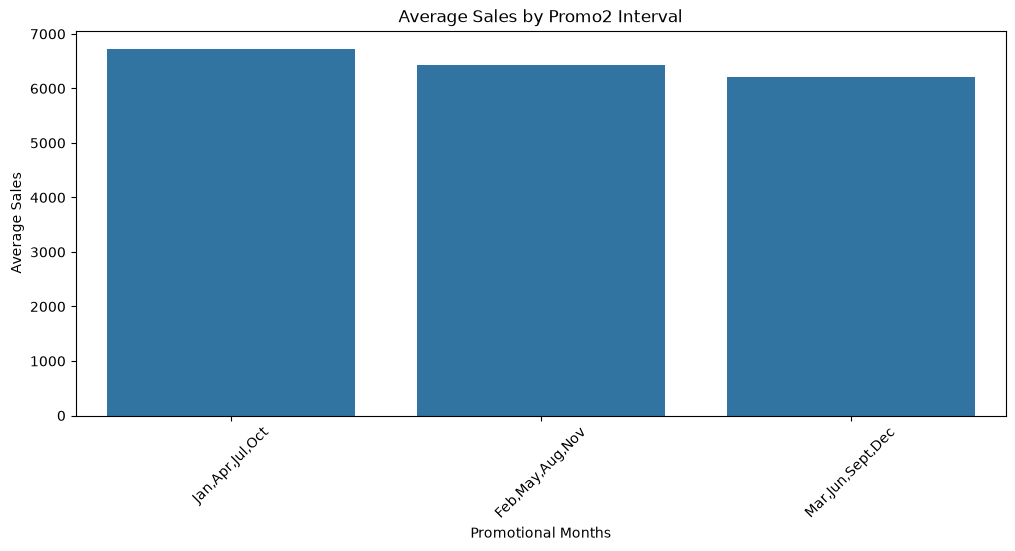

In [163]:

# Check the distribution of promotional intervals
print(train_merged['PromoInterval'].value_counts(dropna=False))

# Compare average sales by promotional interval
sales_by_interval = (
    open_stores.groupby('PromoInterval', dropna=False)['Sales']
    .mean()
    .sort_values(ascending=False)
)

print(sales_by_interval)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=sales_by_interval.index.astype(str),
    y=sales_by_interval.values
)

plt.title('Average Sales by Promo2 Interval')
plt.xlabel('Promotional Months')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()


In [164]:

# Calculate missing values
missing_values = pd.DataFrame({
    'Missing Count': train_merged.isnull().sum(),
    'Missing Percentage': (
        train_merged.isnull().sum() /
        len(train_merged) * 100
    )
})

missing_values = missing_values[
    missing_values['Missing Count'] > 0
].sort_values(
    by='Missing Percentage',
    ascending=False
)

print(missing_values)


                           Missing Count  Missing Percentage
Promo2SinceYear                   508031           49.943620
Promo2SinceWeek                   508031           49.943620
PromoInterval                     508031           49.943620
CompetitionOpenSinceMonth         323348           31.787764
CompetitionOpenSinceYear          323348           31.787764
CompetitionDistance                 2642            0.259730


In [165]:

# Dataset overview
print("Dataset Shape:", train_merged.shape)

print("\nData Types:")
print(train_merged.dtypes)

print("\nNumerical Features:")
print(train_merged.describe())

print("\nCategorical Features:")
print(train_merged.describe(include='object'))

print("\nMissing Values:")
print(train_merged.isnull().sum())


Dataset Shape: (1017209, 18)

Data Types:
Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Customers                             int64
Open                                  int64
Promo                                 int64
StateHoliday                            str
SchoolHoliday                         int64
StoreType                               str
Assortment                              str
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                           str
dtype: object

Numerical Features:
              Store     DayOfWeek                        Date         Sales  \
count  1.017209e+06  1.017209e+06                   

C:\Users\mrymh\AppData\Local\Temp\ipykernel_4800\146127737.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(train_merged.describe(include='object'))


       StateHoliday StoreType Assortment    PromoInterval
count       1017209   1017209    1017209           509178
unique            4         4          3                3
top               0         a          a  Jan,Apr,Jul,Oct
freq         986159    551627     537445           293122

Missing Values:
Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


## Exploratory Data Analysis – Key Findings

1. **Sales Distribution:** Sales are right-skewed, with some unusually high sales values.

2. **Time Trends:** Sales show monthly and yearly variations, with noticeable seasonal patterns, particularly around December.

3. **Customers and Sales:** Sales and Customers have a strong positive correlation.

4. **Promotions:** Stores generally achieve higher average sales when Promo is active.

5. **State Holidays:** Average sales vary across different state holiday categories.

6. **Store Characteristics:** StoreType and Assortment are associated with differences in average sales.

7. **Competition:** CompetitionDistance may provide useful information about store performance.

8. **Promo2:** Participation in continuing promotional programs may help explain differences in sales.

9. **Missing Values:** Several competition and Promo2-related features contain missing values and require further investigation during preprocessing.

### Conclusion

EDA revealed that sales are associated with several factors, including customer numbers, promotions, store characteristics, holidays, and temporal patterns. These findings will guide feature engineering, missing-value treatment, and model development.